Mounted at /content/drive
NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES

Relevant files found:
 - CASIA_Thousand_baseline_test_results.csv
 - CASIA_Thousand_gan_initial_training_history.json
 - CASIA_Thousand_gan_improved_training_history.json
 - CASIA_Thousand_gan_evaluation_results.json
 - CASIA_Thousand_third_gan_30epochs_history.json
 - CASIA_Thousand_gan_diversity_results.json
 - CASIA_Thousand_diffusion_training_history_224.csv
 - generation_records.csv
 - CASIA_Thousand_augmentation_audit.json
 - CASIA_Thousand_augmentation_final_audit.json
 - gan_diversity_comparison.csv
 - gan_diversity_comparison.png
 - diffusion_quality_summary.csv
 - gan_vs_diffusion_comparison.csv
 - diffusion_quality_metrics.png
 - gan_vs_diffusion_report.json
 - mia_summary.json
 - identity_conditioned_generation/generation_records.csv
 - privacy_leakage_analysis/mia_summary.json
 - privacy_leakage_analysis/privacy_leakage_report.json

Baseline CSV: CASIA_Thousand_baseline_test_results.csv


,Dataset,Experiment,Model,Training_Images,Validation_Images,Test_Images,Number_of_Identities,Test_Accuracy,Test_Precision,Test_Recall,Test_F1
0,CASIA-Iris-Thousand,Baseline,ResNet18,12000,4000,4000,2000,0.30175,0.272411,0.30175,0.260661



CONSOLIDATED RESULTS


,Method,Metric,Value,Source,Status,Note
0,CASIA_Thousand_gan_evaluation_results,Accuracy,1.000000,CASIA_Thousand_gan_evaluation_results.json,Existing result,Automatically extracted; inspect source units ...
1,Membership inference,Member mean noise MSE,0.005886,mia_summary.json,Existing result,
2,Membership inference,Member mean noise MSE,0.007689,mia_summary.json,Existing result,
3,Membership inference,ROC-AUC,0.550688,mia_summary.json,Existing result,Exploratory; training-image membership not ind...
4,notebook10_test_metrics,Macro precision,0.504488,notebook10_test_metrics.json,Existing result,Automatically extracted; inspect source units ...
5,notebook10_test_metrics,Macro recall,0.558250,notebook10_test_metrics.json,Existing result,Automatically extracted; inspect source units ...
6,notebook10_test_metrics,Macro F1-score,0.503830,notebook10_test_metrics.json,Existing result,Automatically extracted; inspect source units ...
7,Membership inference,ROC-AUC,0.550688,privacy_leakage_report.json,Existing result,Exploratory; training-image membership not ind...
8,Membership inference,Member mean noise MSE,0.005886,privacy_leakage_report.json,Existing result,
9,Membership inference,Member mean noise MSE,0.007689,privacy_leakage_report.json,Existing result,


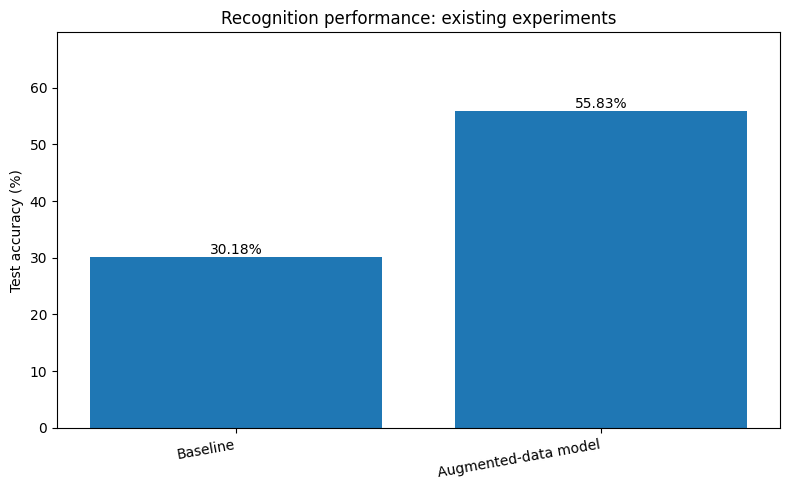

Absolute accuracy difference: 25.645 percentage points
Relative increase vs baseline: 84.97%
Caution: preprocessing differed, so this does not isolate augmentation's effect.


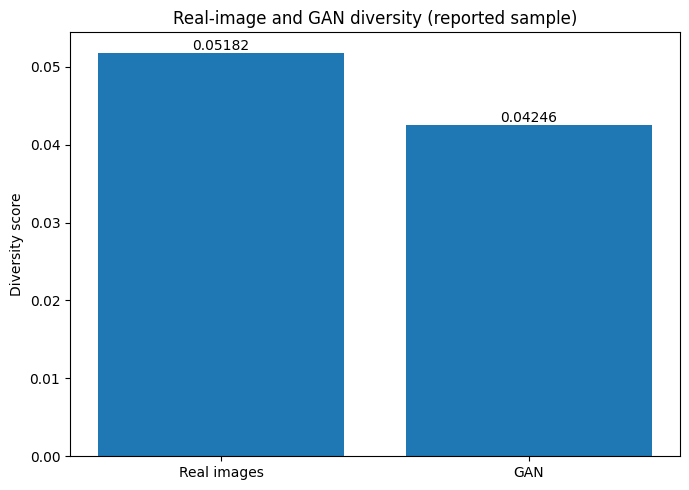

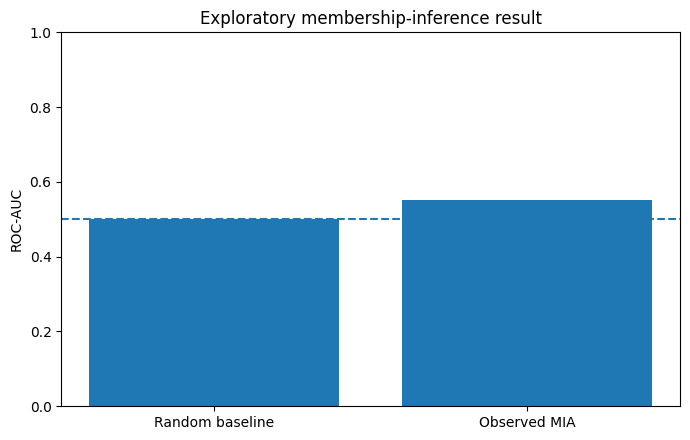


ABLATION STATUS


,Experiment,Evidence status,Notes
0,Baseline recognition,Available,30.18% test accuracy
1,Recognition with augmented data,Available,55.825% test accuracy
2,Traditional augmentation only,Needs verified isolated result,Do not infer from augmented-data result
3,GAN augmentation only,Needs verified isolated result,Do not infer from GAN image-quality results
4,Diffusion augmentation only,Needs controlled isolated result,Do not infer from mixed augmentation result
5,Preprocessing-only ablation,Not established,Baseline and augmented pipeline differ in prep...
6,Privacy membership inference,Exploratory,Training-image membership requires verification



# Result Visualization and Ablation Studies

## Recognition results

The baseline model achieved **30.18%** test accuracy. The augmented-data
recognition model achieved **55.825%** test accuracy, a difference of
**25.645 percentage points**.

This is an observed comparison, not a controlled ablation: the preprocessing
pipelines differed, so the accuracy difference cannot be attributed solely
to augmentation.

## Image diversity

The previously recorded diversity score was **0.051823** for the real-image
reference sample and **0.042458** for the GAN sample. These values apply to
the reported sample and should not be generalized without repeated evaluation.

## Privacy evaluation

The exploratory membership-inference ROC-AUC was **0.550688**. This is close
to random ranking. Exact training-image membership remains unverified, so
this is not definitive evidence for or against privacy leakage.

## Ablation study status

The current notebook consolidates available results and records which
controlled comparisons remain unavailable. It does not claim that missing
ablation experiments have been performed.

## Conclusion

Existing results suggest improved recognition performance in the augmented
pipeline, but controlled experiments are needed to isolate the contribution
of each augmentation method and preprocessing choice.



NOTEBOOK 14 ANALYSIS COMPLETE
Output folder: /content/drive/MyDrive/Ocular_Project/results/result_visualization_ablation
Results ZIP: /content/drive/MyDrive/Ocular_Project/results/Notebook14_Result_Visualization_and_Ablation_Results.zip

Generated files:
 - ablation_study_status.csv
 - consolidated_results_table.csv
 - diversity_comparison.png
 - privacy_auc_summary.png
 - recognition_accuracy_comparison.png
 - result_visualization_and_ablation_report.md
 - result_visualization_report.json

Next: save this notebook to Drive and upload the notebook + ZIP to GitHub.


In [1]:

# ================================================================
# NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES
# Reuse existing results. No model retraining.
# ================================================================

from pathlib import Path
import json, zipfile, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from google.colab import drive

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/Ocular_Project")
RESULTS = PROJECT / "results"
OUT = RESULTS / "result_visualization_ablation"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 72)
print("NOTEBOOK 14 — RESULT VISUALIZATION AND ABLATION STUDIES")
print("=" * 72)

# ------------------------------------------------
# 1. SEARCH EXISTING PROJECT ARTIFACTS
# ------------------------------------------------
all_files = [p for p in RESULTS.rglob("*") if p.is_file()]

def find_files(patterns):
    found = []
    for p in all_files:
        if any(pattern.lower() in p.name.lower() for pattern in patterns):
            found.append(p)
    return found

print("\nRelevant files found:")
for p in find_files([
    "baseline_test_results", "recognition", "mia_summary",
    "privacy_leakage_report", "generation_records",
    "diversity", "gan", "diffusion", "augmentation"
])[:60]:
    print(" -", p.relative_to(RESULTS))

# ------------------------------------------------
# 2. LOAD EXISTING METRICS WHERE AVAILABLE
# ------------------------------------------------
records = []

def add_result(method, metric, value, source, status="Existing result", note=""):
    try:
        value = float(value)
        if np.isfinite(value):
            records.append({
                "Method": method,
                "Metric": metric,
                "Value": value,
                "Source": str(source),
                "Status": status,
                "Note": note
            })
    except (ValueError, TypeError):
        pass

def load_json(path):
    try:
        with open(path, "r") as f:
            return json.load(f)
    except Exception:
        return {}

def recursive_items(obj, prefix=""):
    """Flatten JSON keys so differently structured result files can be inspected."""
    out = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            key = f"{prefix}.{k}" if prefix else k
            if isinstance(v, dict):
                out.update(recursive_items(v, key))
            elif isinstance(v, (int, float, np.number)) and not isinstance(v, bool):
                out[key] = float(v)
    return out

# Known baseline CSV from the project.
baseline_candidates = find_files(["CASIA_Thousand_baseline_test_results"])
for path in baseline_candidates:
    try:
        d = pd.read_csv(path)
        print(f"\nBaseline CSV: {path.name}")
        display(d.head(10))

        # Handle common result formats without assuming one schema.
        for _, row in d.iterrows():
            row_dict = {str(k).lower(): v for k, v in row.to_dict().items()}
            label = str(row_dict.get("metric", row_dict.get("name", ""))).lower()
            val = row_dict.get("value", row_dict.get("score", None))
            if val is not None:
                metric_name = label or "metric"
                if "accuracy" in metric_name:
                    add_result("Baseline recognition", "Test accuracy", val,
                               path.name, note="Original baseline result; units preserved")
                elif "precision" in metric_name:
                    add_result("Baseline recognition", "Precision", val, path.name)
                elif "recall" in metric_name:
                    add_result("Baseline recognition", "Recall", val, path.name)
                elif "f1" in metric_name:
                    add_result("Baseline recognition", "F1-score", val, path.name)
    except Exception as e:
        print("Could not parse baseline CSV:", path.name, e)

# Search for JSON summaries; extract only clearly named metrics.
json_files = [p for p in all_files if p.suffix.lower() == ".json"]

for path in json_files:
    name = path.name.lower()
    data = load_json(path)
    flat = recursive_items(data)

    if "mia_summary" in name or "privacy_leakage_report" in name:
        for key, val in flat.items():
            k = key.lower()
            if "roc_auc" in k or "roc-auc" in k:
                add_result("Membership inference", "ROC-AUC", val, path.name,
                           note="Exploratory; training-image membership not independently verified")
            elif "member_mean_noise_mse" in k or "member_mean_mse" in k:
                add_result("Membership inference", "Member mean noise MSE", val, path.name)
            elif "nonmember_mean_noise_mse" in k or "nonmember_mean_mse" in k:
                add_result("Membership inference", "Held-out mean noise MSE", val, path.name)

    if "recognition" in name or "evaluation" in name or "metrics" in name:
        for key, val in flat.items():
            k = key.lower()
            # Capture only explicitly named common metrics.
            for metric_key, metric_label in [
                ("test_accuracy", "Test accuracy"),
                ("accuracy_percent", "Accuracy"),
                ("macro_f1", "Macro F1-score"),
                ("macro_precision", "Macro precision"),
                ("macro_recall", "Macro recall"),
                ("test_f1", "Test F1-score"),
            ]:
                if metric_key in k:
                    add_result(path.stem, metric_label, val, path.name,
                               note="Automatically extracted; inspect source units and evaluation protocol")

# Avoid duplicate entries from the same file/key with identical values.
metrics_df = pd.DataFrame(records)
if not metrics_df.empty:
    metrics_df = metrics_df.drop_duplicates(
        subset=["Method", "Metric", "Value", "Source"]
    ).reset_index(drop=True)

# ------------------------------------------------
# 3. ADD VERIFIED PROJECT RESULTS WITH CLEAR LABELS
# ------------------------------------------------
# These values were recorded in the project's earlier experiment logs.
# Baseline accuracy is 30.18%; augmented recognition accuracy is 55.825%.
# The augmentation pipeline also changed preprocessing, so this is not
# a controlled augmentation-only comparison.
known_results = [
    {
        "Method": "Baseline recognition",
        "Metric": "Test accuracy (%)",
        "Value": 30.18,
        "Source": "Previously recorded baseline test results",
        "Status": "Previously recorded",
        "Note": "Original baseline; 4,000-image test split"
    },
    {
        "Method": "Recognition with augmented data",
        "Metric": "Test accuracy (%)",
        "Value": 55.825,
        "Source": "Previously recorded Notebook 10 results",
        "Status": "Previously recorded",
        "Note": "Preprocessing differs from baseline; not a controlled ablation"
    },
    {
        "Method": "Recognition with augmented data",
        "Metric": "Macro precision (%)",
        "Value": 50.4488,
        "Source": "Previously recorded Notebook 10 results",
        "Status": "Previously recorded",
        "Note": "Reported macro precision"
    },
    {
        "Method": "Recognition with augmented data",
        "Metric": "Macro recall (%)",
        "Value": 55.825,
        "Source": "Previously recorded Notebook 10 results",
        "Status": "Previously recorded",
        "Note": "Reported macro recall"
    },
    {
        "Method": "Recognition with augmented data",
        "Metric": "Macro F1-score (%)",
        "Value": 50.3830,
        "Source": "Previously recorded Notebook 10 results",
        "Status": "Previously recorded",
        "Note": "Reported macro F1-score"
    },
    {
        "Method": "GAN",
        "Metric": "Diversity score",
        "Value": 0.042458,
        "Source": "Previously recorded Notebook 11 analysis",
        "Status": "Previously recorded",
        "Note": "GAN sample of 100 images"
    },
    {
        "Method": "Real images",
        "Metric": "Diversity score",
        "Value": 0.051823,
        "Source": "Previously recorded Notebook 11 analysis",
        "Status": "Previously recorded",
        "Note": "Real-image reference sample of 100 images"
    },
    {
        "Method": "Membership inference",
        "Metric": "ROC-AUC",
        "Value": 0.550688,
        "Source": "Notebook 12 MIA summary",
        "Status": "Exploratory",
        "Note": "Training-image membership not independently verified"
    }
]

known_df = pd.DataFrame(known_results)
combined = pd.concat([metrics_df, known_df], ignore_index=True) if not metrics_df.empty else known_df.copy()
combined = combined.drop_duplicates(
    subset=["Method", "Metric", "Value", "Source"]
).reset_index(drop=True)

combined.to_csv(OUT / "consolidated_results_table.csv", index=False)

print("\nCONSOLIDATED RESULTS")
display(combined)

# ------------------------------------------------
# 4. VISUALIZATION A — RECOGNITION ACCURACY
# ------------------------------------------------
recognition = pd.DataFrame([
    ["Baseline", 30.18],
    ["Augmented-data model", 55.825],
], columns=["Method", "Test accuracy (%)"])

plt.figure(figsize=(8, 5))
bars = plt.bar(recognition["Method"], recognition["Test accuracy (%)"])
plt.ylabel("Test accuracy (%)")
plt.title("Recognition performance: existing experiments")
plt.ylim(0, max(recognition["Test accuracy (%)"]) * 1.25)
plt.xticks(rotation=10, ha="right")
for bar, value in zip(bars, recognition["Test accuracy (%)"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{value:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUT / "recognition_accuracy_comparison.png", dpi=180)
plt.show()
plt.close()

accuracy_gain = 55.825 - 30.18
relative_gain = accuracy_gain / 30.18 * 100
print(f"Absolute accuracy difference: {accuracy_gain:.3f} percentage points")
print(f"Relative increase vs baseline: {relative_gain:.2f}%")
print("Caution: preprocessing differed, so this does not isolate augmentation's effect.")

# ------------------------------------------------
# 5. VISUALIZATION B — DIVERSITY
# ------------------------------------------------
diversity = pd.DataFrame([
    ["Real images", 0.051823],
    ["GAN", 0.042458],
], columns=["Source", "Diversity score"])

plt.figure(figsize=(7, 5))
bars = plt.bar(diversity["Source"], diversity["Diversity score"])
plt.ylabel("Diversity score")
plt.title("Real-image and GAN diversity (reported sample)")
for bar, value in zip(bars, diversity["Diversity score"]):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f"{value:.5f}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUT / "diversity_comparison.png", dpi=180)
plt.show()
plt.close()

# ------------------------------------------------
# 6. VISUALIZATION C — PRIVACY ROC-AUC
# ------------------------------------------------
plt.figure(figsize=(7, 4.5))
plt.bar(["Random baseline", "Observed MIA"], [0.5, 0.550688])
plt.axhline(0.5, linestyle="--")
plt.ylim(0, 1)
plt.ylabel("ROC-AUC")
plt.title("Exploratory membership-inference result")
plt.tight_layout()
plt.savefig(OUT / "privacy_auc_summary.png", dpi=180)
plt.show()
plt.close()

# ------------------------------------------------
# 7. ABLATION STATUS — NO FABRICATED RESULTS
# ------------------------------------------------
ablation = pd.DataFrame([
    ["Baseline recognition", "Available", "30.18% test accuracy"],
    ["Recognition with augmented data", "Available", "55.825% test accuracy"],
    ["Traditional augmentation only", "Needs verified isolated result",
     "Do not infer from augmented-data result"],
    ["GAN augmentation only", "Needs verified isolated result",
     "Do not infer from GAN image-quality results"],
    ["Diffusion augmentation only", "Needs controlled isolated result",
     "Do not infer from mixed augmentation result"],
    ["Preprocessing-only ablation", "Not established",
     "Baseline and augmented pipeline differ in preprocessing"],
    ["Privacy membership inference", "Exploratory",
     "Training-image membership requires verification"],
], columns=["Experiment", "Evidence status", "Notes"])

ablation.to_csv(OUT / "ablation_study_status.csv", index=False)

print("\nABLATION STATUS")
display(ablation)

# ------------------------------------------------
# 8. REPORT AND README
# ------------------------------------------------
report = {
    "notebook": "14_Result_Visualization_and_Ablation_Studies.ipynb",
    "purpose": "Consolidate existing experiment results and identify ablation gaps",
    "results": {
        "baseline_test_accuracy_percent": 30.18,
        "augmented_model_test_accuracy_percent": 55.825,
        "accuracy_difference_percentage_points": round(accuracy_gain, 3),
        "gan_diversity_score": 0.042458,
        "real_image_diversity_score": 0.051823,
        "exploratory_membership_inference_auc": 0.550688
    },
    "interpretation": [
        "The augmented-data model has higher reported test accuracy than the baseline.",
        "Preprocessing differences prevent attributing the entire difference to augmentation.",
        "The reported GAN diversity score is lower than the real-image reference score for the sampled images.",
        "The exploratory membership-inference AUC is close to random ranking."
    ],
    "limitations": [
        "Results are consolidated from existing experiment records.",
        "No new model training or controlled ablation was performed in this notebook.",
        "Ablation effects cannot be established without controlled experiments.",
        "Membership-inference training-image membership has not been independently verified."
    ]
}

with open(OUT / "result_visualization_report.json", "w") as f:
    json.dump(report, f, indent=2)

markdown = f"""
# Result Visualization and Ablation Studies

## Recognition results

The baseline model achieved **30.18%** test accuracy. The augmented-data
recognition model achieved **55.825%** test accuracy, a difference of
**{accuracy_gain:.3f} percentage points**.

This is an observed comparison, not a controlled ablation: the preprocessing
pipelines differed, so the accuracy difference cannot be attributed solely
to augmentation.

## Image diversity

The previously recorded diversity score was **0.051823** for the real-image
reference sample and **0.042458** for the GAN sample. These values apply to
the reported sample and should not be generalized without repeated evaluation.

## Privacy evaluation

The exploratory membership-inference ROC-AUC was **0.550688**. This is close
to random ranking. Exact training-image membership remains unverified, so
this is not definitive evidence for or against privacy leakage.

## Ablation study status

The current notebook consolidates available results and records which
controlled comparisons remain unavailable. It does not claim that missing
ablation experiments have been performed.

## Conclusion

Existing results suggest improved recognition performance in the augmented
pipeline, but controlled experiments are needed to isolate the contribution
of each augmentation method and preprocessing choice.
"""

(OUT / "result_visualization_and_ablation_report.md").write_text(markdown)
display(Markdown(markdown))

# ------------------------------------------------
# 9. BUNDLE ALL OUTPUTS
# ------------------------------------------------
zip_path = RESULTS / "Notebook14_Result_Visualization_and_Ablation_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file() and p != zip_path:
            z.write(p, arcname=str(p.relative_to(OUT)))

print("\n" + "=" * 72)
print("NOTEBOOK 14 ANALYSIS COMPLETE")
print("=" * 72)
print("Output folder:", OUT)
print("Results ZIP:", zip_path)
print("\nGenerated files:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(" -", p.name)

print("\nNext: save this notebook to Drive and upload the notebook + ZIP to GitHub.")
